# Rate maps per second vs per sniff

The usual rate map divides each bin's spike count by the time spent there (spikes / s). If the animal sniffs faster
in some places, and a unit fires more when the animal sniffs faster, that map shows a field that is really a sniff-rate
field. Dividing the rate map by the **sniff-rate map** (sniffs / s in the same bin) gives **spikes per sniff**, which
takes sniff rate out:

| map | per bin | units |
|---|---|---|
| rate | spikes / occupancy | Hz |
| sniff rate | sniffs / occupancy | Hz |
| per sniff | rate / sniff rate = spikes / sniffs | spikes per sniff |

Bins, epochs and spike alignment are those of `spatial_info.py` (129 px bins over the fixed arena, 7 x 15; spikes and
inhalations take the bin of their nearest tracked frame). Sniffs are the good inhalations of `sniff_params.mat`. Both
maps use the same bins: at least 0.1 s of occupancy and at least 10 sniffs. Maps are not smoothed.

Scores (from `sniff_rate_map.py`, `E:/cbm-odor/sniff/sniff_rate_map_<epoch>.csv`), both Skaggs information in bits/spike:

- **si_rate**: the usual SI, how far the spikes' spatial distribution is from the occupancy distribution.
- **si_sniff**: the same with sniffs as the occupancy, how far the spikes' spatial distribution is from the sniffs'.
  A unit whose place field is just sniff rate has high si_rate and si_sniff near its null.
- **\*_z, \*_p**: against 500 circular shifts of the spikes within the epoch's frames. The trajectory and sniffs stay
  put, and both scores use the same shifts.
- **si_sniffing** (per session, bits/sniff): how far the sniffs' spatial distribution is from occupancy, i.e. how
  unevenly sniff rate is spread over the arena.

`si_rate` here is close to `spatial_info.py`'s but not identical: bins also need 10 sniffs, and the null shifts frames
rather than time. Rerun the scores with `python sniff_rate_map.py` from `sniff-raster-python/`.

In [1]:
import sys
sys.path.insert(0, 'sniff-raster-python')  # the analysis modules live there
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sniff_rate_map as srm
from sniff_rate_map import MapSession, plot_maps

EPOCH = 'appetitive'  # 'all', 'appetitive' or 'consummatory'
ALPHA = 0.05
keys = ['mouse', 'session', 'region', 'cluster']
base = srm.OUT_FILE[:-len('.csv')]
scores = {e: pd.read_csv(f'{base}_{e}.csv', dtype={'mouse': str}) for e in srm.EPOCHS}
sniff_lock = pd.read_csv('E:/cbm-odor/sniff/sniff_locking.csv', dtype={'mouse': str})
for e in scores:
    scores[e] = scores[e].merge(sniff_lock[keys + ['info_z', 'info_p']], on=keys, how='left', validate='one_to_one')
df = scores[EPOCH].dropna(subset=['si_rate', 'si_sniff'])
print(f'{EPOCH}: {len(df)} scored units ({df.region.value_counts().to_dict()})')

appetitive: 4909 scored units ({'hc': 2941, 'ob': 1968})


## How much does sniff rate vary over the arena?

Sniff-rate maps of a few sessions, and `si_sniffing` across sessions. If sniff rate were flat, the two kinds of rate map
would be the same up to a constant.

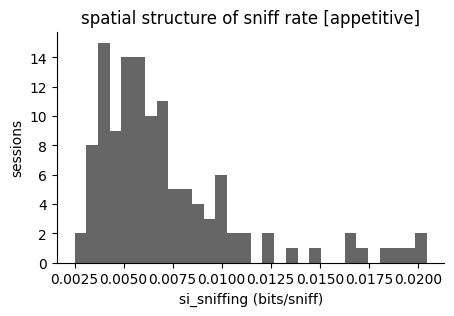

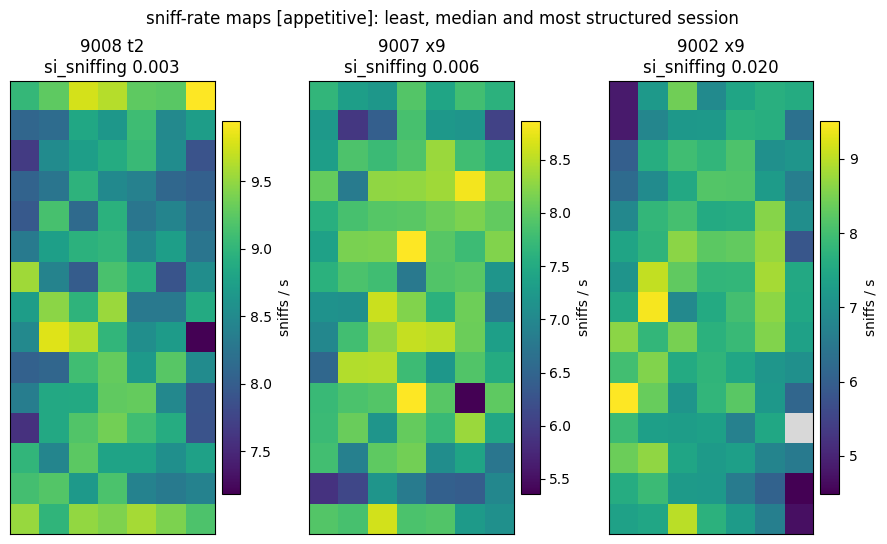

In [2]:
sessions = {}  # loaded sessions, shared by the cells below


def get_session(mouse, session):
    key = (str(mouse), session)
    if key not in sessions:
        sessions[key] = MapSession(*key)
    return sessions[key]


per_session = scores[EPOCH].drop_duplicates(['mouse', 'session'])[['mouse', 'session', 'si_sniffing', 'n_sniffs_epoch']]
fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(per_session['si_sniffing'].dropna(), bins=30, color='0.4')
ax.set(xlabel='si_sniffing (bits/sniff)', ylabel='sessions', title=f'spatial structure of sniff rate [{EPOCH}]')
ax.spines[['top', 'right']].set_visible(False)
plt.show()

# sessions with the least, median and most spatially structured sniffing
ranked = per_session.dropna().sort_values('si_sniffing')
picks = ranked.iloc[[0, len(ranked) // 2, -1]]
fig, axes = plt.subplots(1, 3, figsize=(9, 5.5))
extent = (*srm.si.ARENA_X_RANGE_PX, srm.si.ARENA_Y_RANGE_PX[1], srm.si.ARENA_Y_RANGE_PX[0])
cmap = plt.get_cmap('viridis').with_extremes(bad='0.85')
for ax, (_, s) in zip(axes, picks.iterrows()):
    ms = get_session(s['mouse'], s['session'])
    v = ms.valid[EPOCH]
    with np.errstate(divide='ignore', invalid='ignore'):
        sr = np.where(v, ms.n_sniffs[EPOCH] / ms.occ_s[EPOCH], np.nan)
    im = ax.imshow(ms.grid(sr), cmap=cmap, extent=extent, interpolation='nearest')
    ax.set(xticks=[], yticks=[], title=f"{s['mouse']} {s['session']}\nsi_sniffing {s['si_sniffing']:.3f}")
    fig.colorbar(im, ax=ax, fraction=0.08, pad=0.03, label='sniffs / s')
fig.suptitle(f'sniff-rate maps [{EPOCH}]: least, median and most structured session')
fig.tight_layout()
plt.show()

## Population: SI per second vs SI per sniff

Each dot is a unit. Points below the diagonal lose spatial information once sniff rate is divided out. The table counts
units significant (`p < 0.05`) by either measure.

Caveat: z-scores drop somewhat even for units whose rate map does not follow sniff rate (hc, median `r_rate_sniff`
near 0). Per-bin sniff counts are noisy, so dividing by them widens the null. Compare OB against hc as a baseline,
and use `r_rate_sniff` (next sections) for how much of a map is sniff rate.

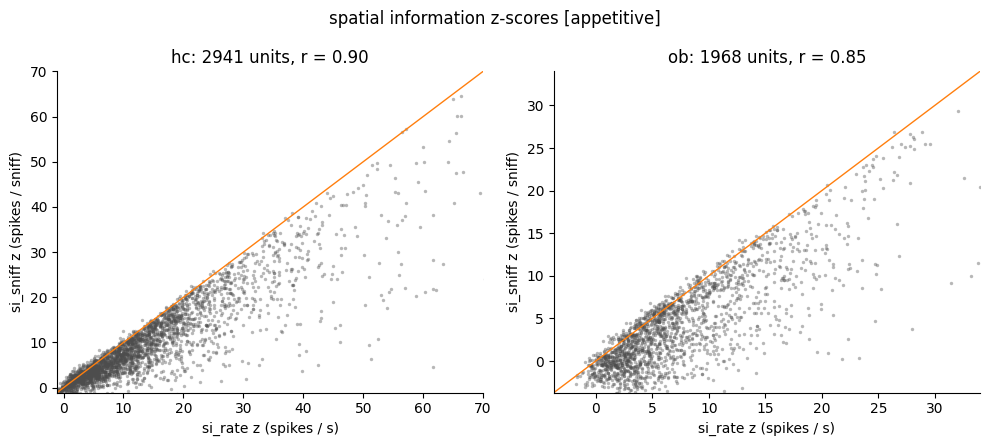

,rate ns / sniff ns,rate ns / sniff sig,rate sig / sniff ns,rate sig / sniff sig
region,,,,
hc,200,35,197,2509
ob,247,11,526,1184


,si_rate,si_sniff,si_rate_z,si_sniff_z,r_rate_sniff,r_rate_per_sniff
median [appetitive],,,,,,
hc,0.041,0.048,11.236,7.186,-0.018,0.928
ob,0.032,0.036,5.865,3.120,0.119,0.899


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (region, d) in zip(axes, df.groupby('region')):
    ax.scatter(d['si_rate_z'], d['si_sniff_z'], s=6, alpha=0.4, c='0.3', lw=0)
    lim = np.nanpercentile(np.r_[d['si_rate_z'], d['si_sniff_z']], [0.5, 99.5])
    ax.plot(lim, lim, color='C1', lw=1)
    r = d[['si_rate_z', 'si_sniff_z']].corr().iat[0, 1]
    ax.set(xlim=lim, ylim=lim, xlabel='si_rate z (spikes / s)', ylabel='si_sniff z (spikes / sniff)',
           title=f'{region}: {len(d)} units, r = {r:.2f}')
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle(f'spatial information z-scores [{EPOCH}]')
fig.tight_layout()
plt.show()

sig = df.assign(rate=df['si_rate_p'] < ALPHA, sniff=df['si_sniff_p'] < ALPHA)
counts = sig.groupby(['region', 'rate', 'sniff']).size().unstack(['rate', 'sniff'], fill_value=0)
counts.columns = [f'rate {"sig" if a else "ns"} / sniff {"sig" if b else "ns"}' for a, b in counts.columns]
display(counts)

summary = df.groupby('region')[['si_rate', 'si_sniff', 'si_rate_z', 'si_sniff_z', 'r_rate_sniff', 'r_rate_per_sniff']].median()
display(summary.round(3).rename_axis(f'median [{EPOCH}]'))

## All epochs

The same comparison for every epoch: fraction of units significant by each measure, and the median z-scores.

In [4]:
rows = []
for e, d in scores.items():
    d = d.dropna(subset=['si_rate', 'si_sniff'])
    for region, g in d.groupby('region'):
        rows.append(dict(epoch=e, region=region, n=len(g),
                         frac_sig_rate=(g['si_rate_p'] < ALPHA).mean(), frac_sig_sniff=(g['si_sniff_p'] < ALPHA).mean(),
                         median_rate_z=g['si_rate_z'].median(), median_sniff_z=g['si_sniff_z'].median(),
                         median_r_rate_sniff=g['r_rate_sniff'].median()))
display(pd.DataFrame(rows).set_index(['epoch', 'region']).round(3))

n  frac_sig_rate  frac_sig_sniff  median_rate_z  \
epoch        region                                                       
all          hc      2941          0.962           0.729         16.794   
             ob      1968          0.928           0.578          9.161   
appetitive   hc      2941          0.920           0.865         11.236   
             ob      1968          0.869           0.607          5.865   
consummatory hc      2941          0.753           0.589          4.153   
             ob      1968          0.680           0.393          3.214   

                     median_sniff_z  median_r_rate_sniff  
epoch        region                                       
all          hc               5.265                0.001  
             ob               3.137                0.117  
appetitive   hc               7.186               -0.018  
             ob               3.120                0.119  
consummatory hc               2.426                0.011  
             ob               0.765                0.136

## Does sniff-locking predict the drop?

If the "place" in a rate map comes from sniff rate, the units that lose the most should be the ones that follow
sniffing. Left: whole-session sniff-locking (`info_z`, `sniff_locking.py`, symlog axis) against how much the SI z-score
drops after dividing by sniff rate. Right: the drop against how closely the unit's rate map follows the sniff-rate map.

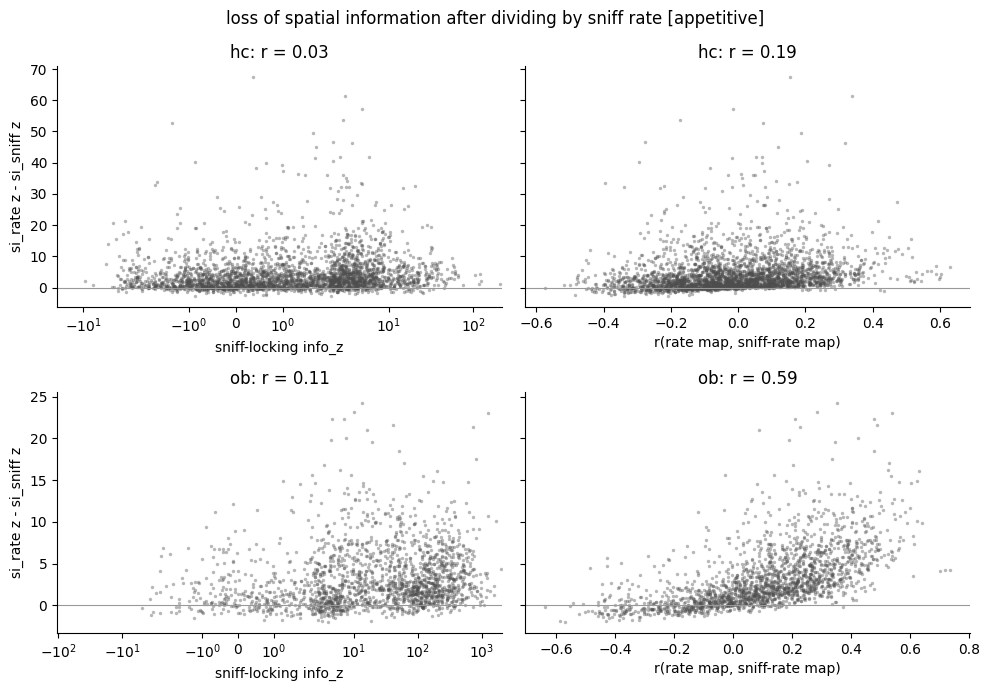

In [5]:
d = df.assign(drop=df['si_rate_z'] - df['si_sniff_z'])
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharey='row')
for row, (region, g) in zip(axes, d.groupby('region')):
    for ax, x, label in zip(row, ['info_z', 'r_rate_sniff'], ['sniff-locking info_z', 'r(rate map, sniff-rate map)']):
        ax.scatter(g[x], g['drop'], s=6, alpha=0.4, c='0.3', lw=0)
        ax.axhline(0, color='0.6', lw=0.8)
        r = g[[x, 'drop']].corr().iat[0, 1]
        ax.set(xlabel=label, title=f'{region}: r = {r:.2f}')
        if x == 'info_z':
            ax.set_xscale('symlog')
        ax.spines[['top', 'right']].set_visible(False)
    row[0].set_ylabel('si_rate z - si_sniff z')
fig.suptitle(f'loss of spatial information after dividing by sniff rate [{EPOCH}]')
fig.tight_layout()
plt.show()

## Example units

Rate map, sniff-rate map, spikes per sniff, and each bin's firing rate against its sniff rate. The orange line is the
unit's mean spikes per sniff: bins on it fire as expected from their sniff rate alone. Grey bins have too little
occupancy or fewer than 10 sniffs. Each map has its own color scale.

First the place-tuned units (`si_rate_p < 0.05`) that lose the most, then those that keep the most.

largest drop


,mouse,session,region,cluster,n_spikes_epoch,si_rate_z,si_sniff_z,drop,r_rate_sniff,info_z
1067,9002,x6,ob,10,68811.0,27.98,3.78,24.20,0.35,13.36
1109,9002,x7,ob,7,55333.0,33.18,10.01,23.17,0.29,9.99
4642,9009,x2,ob,2,56157.0,23.32,0.30,23.02,0.54,1251.20


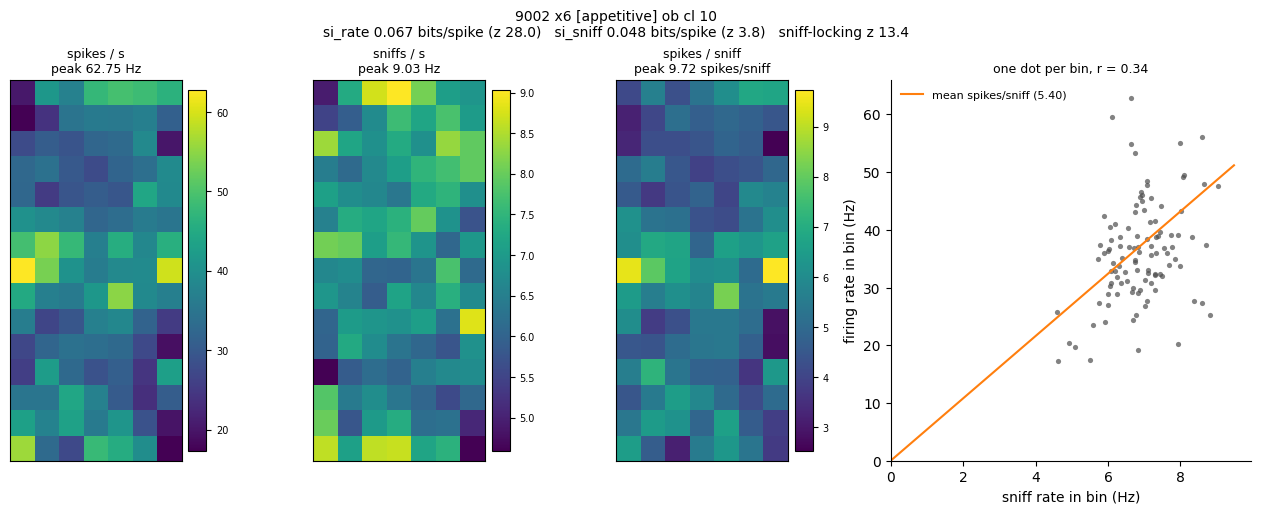

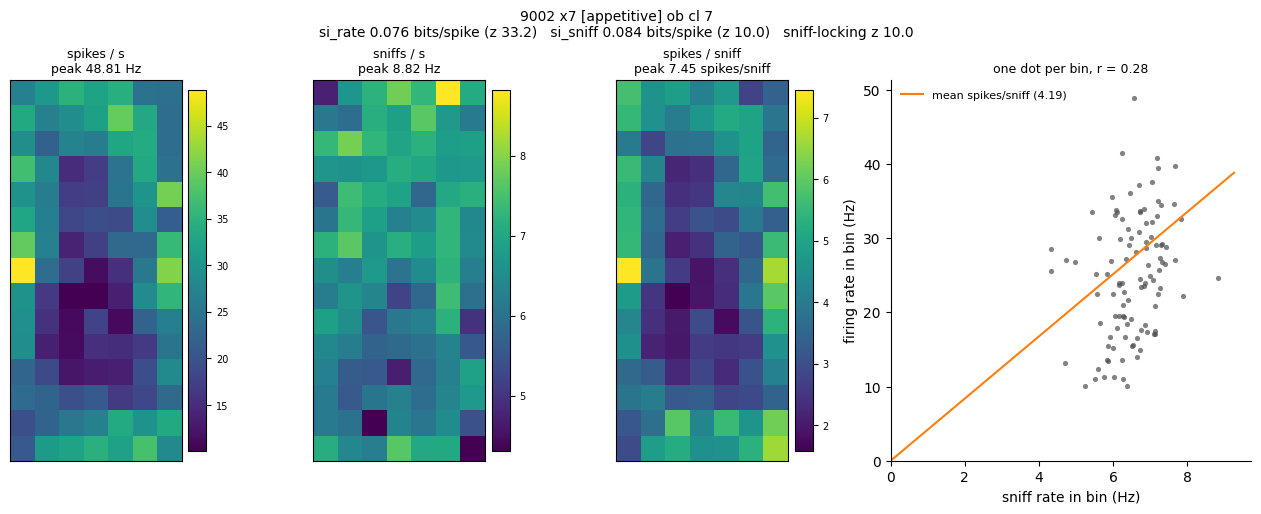

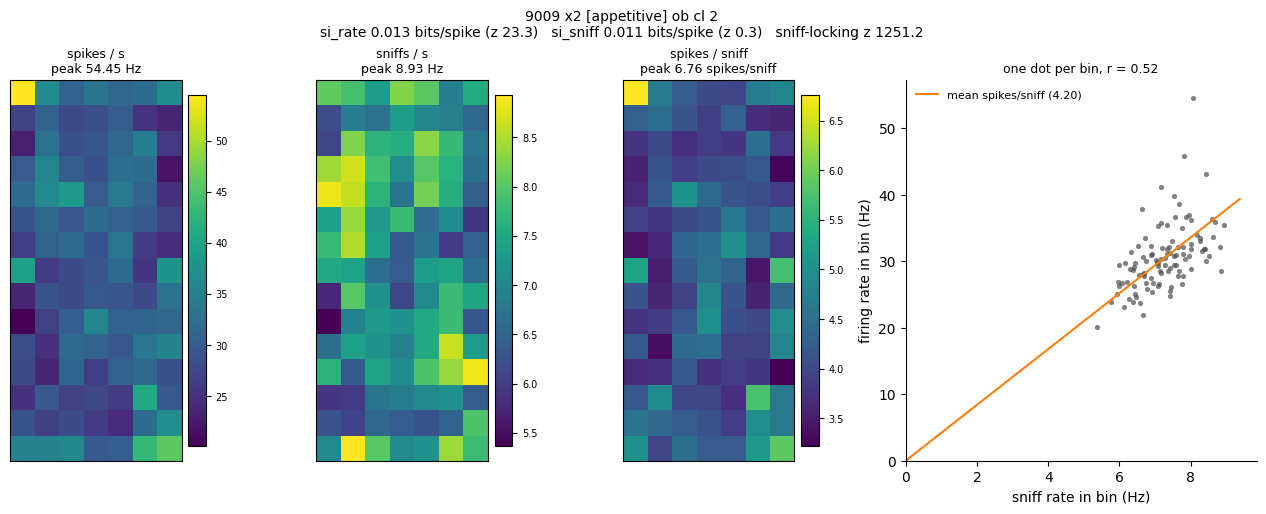

smallest drop


,mouse,session,region,cluster,n_spikes_epoch,si_rate_z,si_sniff_z,drop,r_rate_sniff,info_z
3089,9006,x5,ob,3,20286.0,4.81,6.81,-1.99,-0.57,3.94
3237,9006,x8,ob,16,81578.0,4.03,5.94,-1.90,-0.43,3.20
2973,9006,x3,ob,49,52991.0,7.97,9.75,-1.78,-0.39,2.78


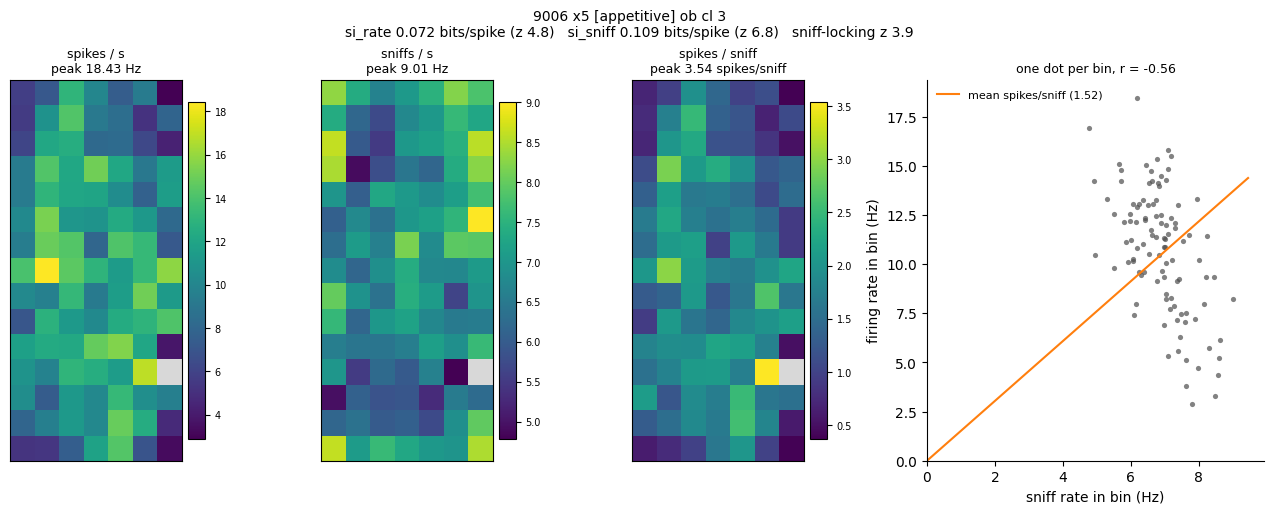

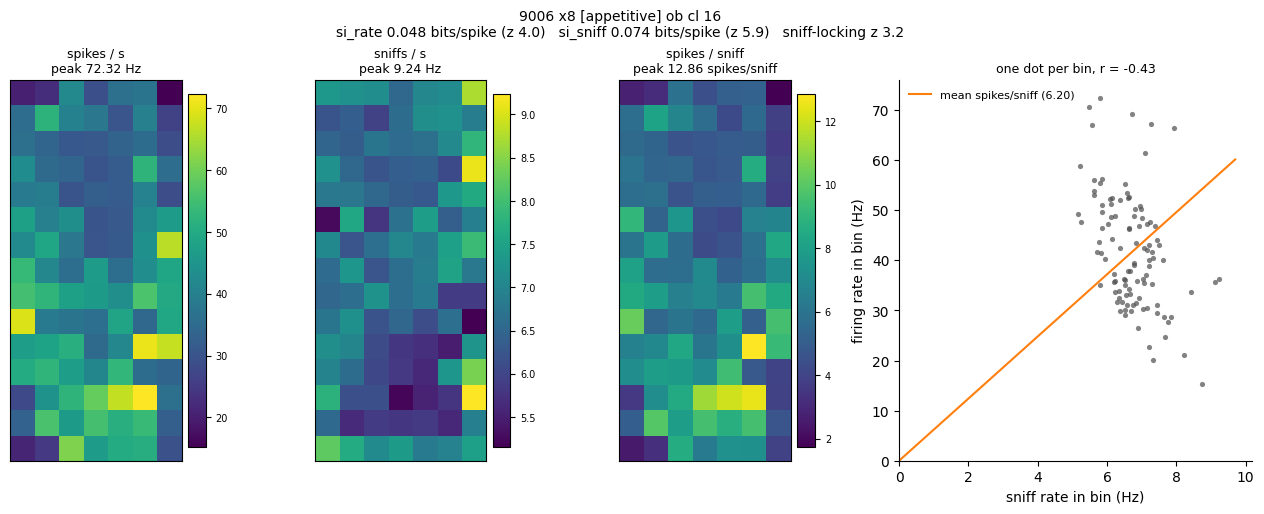

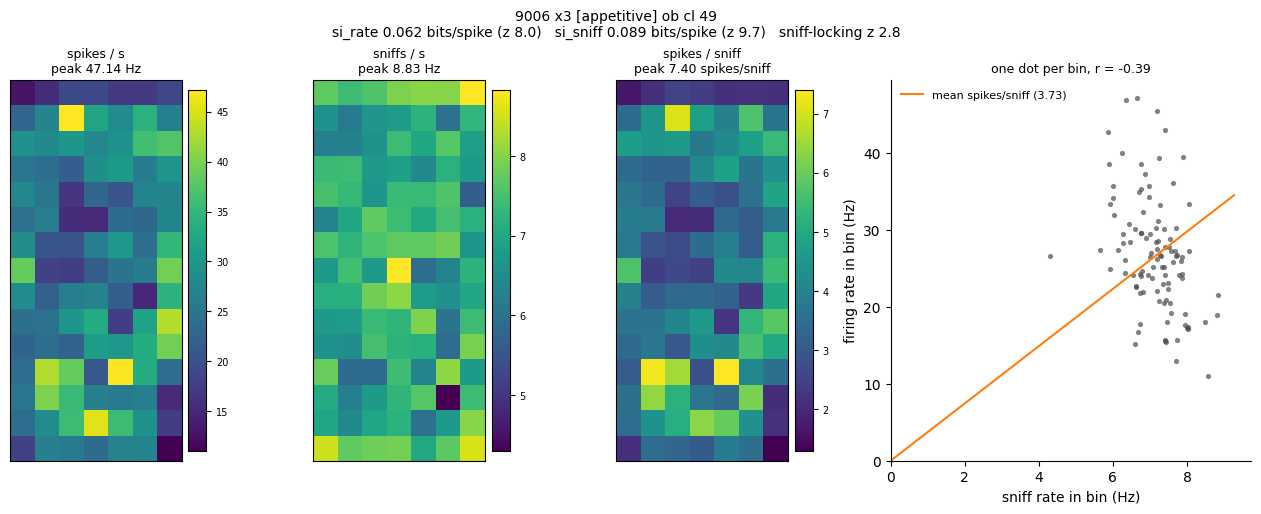

In [6]:
N_UNITS = 3
REGION = 'ob'


def unit_maps(mouse, session, cluster, region='ob', epoch=None, save_path=None):
    """Rate, sniff-rate and spikes-per-sniff maps of one unit, titled with its scores."""
    epoch = epoch or EPOCH
    ms = get_session(mouse, session)
    ks = f'{srm.si.DATA_ROOT}{region}-ks/{mouse}/{session}/'
    st, cl = np.load(ks + 'spike_times.npy').ravel(), np.load(ks + 'spike_clusters.npy').ravel()
    spikes = st[cl == cluster].astype(float) / srm.si.FS_KHZ
    s = scores[epoch]
    row = s[(s['mouse'] == str(mouse)) & (s['session'] == session) & (s['region'] == region) & (s['cluster'] == cluster)]
    title = f' {region} cl {cluster}'
    if not row.empty and pd.notna(row['si_rate'].iat[0]):
        r = row.iloc[0]
        title += (f"\nsi_rate {r['si_rate']:.3f} bits/spike (z {r['si_rate_z']:.1f})   "
                  f"si_sniff {r['si_sniff']:.3f} bits/spike (z {r['si_sniff_z']:.1f})   sniff-locking z {r['info_z']:.1f}")
    return plot_maps(ms, spikes, epoch, title, save_path)


placey = d[(d['region'] == REGION) & (d['si_rate_p'] < ALPHA)]
cols = keys + ['n_spikes_epoch', 'si_rate_z', 'si_sniff_z', 'drop', 'r_rate_sniff', 'info_z']
for label, units in [('largest drop', placey.nlargest(N_UNITS, 'drop')),
                     ('smallest drop', placey.nsmallest(N_UNITS, 'drop'))]:
    print(label)
    display(units[cols].round(2))
    for _, u in units.iterrows():
        unit_maps(u['mouse'], u['session'], u['cluster'], u['region'])

## Any unit

`unit_maps(mouse, session, cluster, region='ob', epoch=None, save_path=None)` plots one unit (`epoch` defaults to
`EPOCH`) and returns its flat maps. Pass `save_path` to also write a PNG.

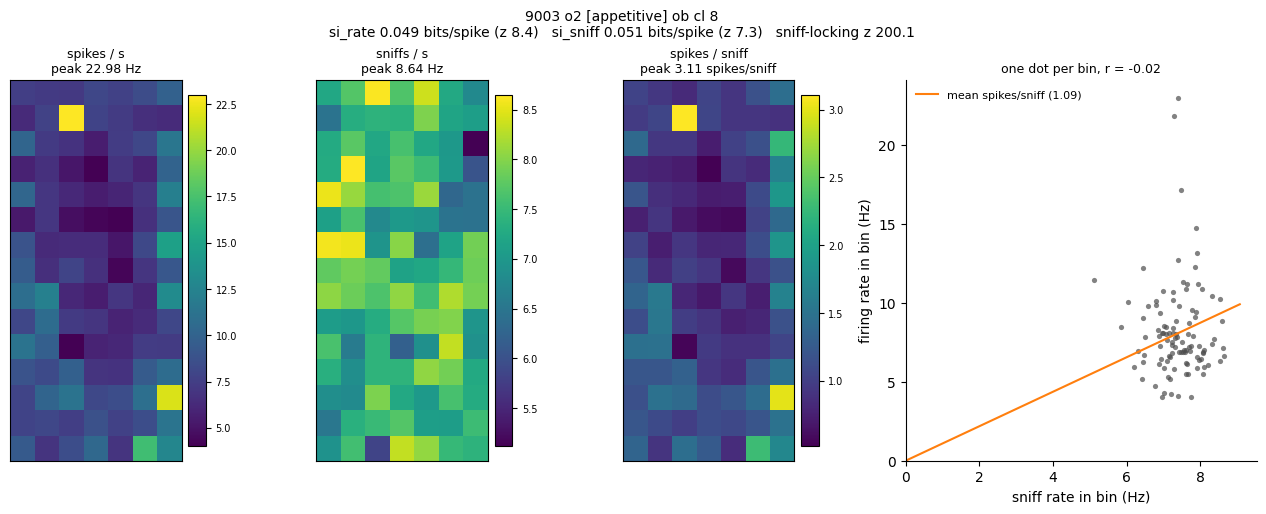

In [7]:
unit_maps('9003', 'o2', 8);